# Pronóstico de heladas a corto plazo (1–6 h)

**Objetivo**: desde una hora de emisión *t* (entre la tarde y la madrugada), estimar con los datos de la propia estación:

1. la **probabilidad de helada** a la hora *t+h* (`temperatura_minima ≤ 0 °C`), para h = 1…6;
2. la **temperatura mínima** esperada a la hora *t+h*;
3. una **alerta acumulada**: ¿habrá helada en algún momento de las próximas 6 h?

**Datos**: las estaciones con heladas y datos de buena calidad, según la evaluación anterior: J1 Apata, J2 El Mantaro, J3 Muqui, J4 Acolla (solo hasta 2024), P1 Camacani, P2 Illpa, P3 Tahuaco, P4 Rincón de la Cruz y C2 USI. Entrenamos un **modelo conjunto** para todas, con la altitud y la latitud como predictores, para que generalice mejor.

**Validación temporal**, sin mezclar años:

| Conjunto | Periodo | Uso |
|---|---|---|
| entrenamiento | hasta 2023-12-31 | ajustar los modelos |
| validación | 2024 | elegir el umbral de alerta |
| prueba | desde 2025-01-01 | evaluación final independiente |

**Modelos comparados**

* **Persistencia**: predice helada en *t+h* si ya hay helada en *t*.
* **Extrapolación**: T(t+h) = T(t) + h · (tasa de enfriamiento de las últimas 3 h).
* **Regresión logística** con todos los predictores.
* **Gradient boosting** (`HistGradientBoosting` de scikit-learn), en versión clasificador (probabilidad) y regresor (Tmin).

Evaluamos todos los casos y, por separado, los **casos de inicio**: aquellos en que todavía no hay helada en *t*. En ellos la persistencia no sirve y es donde de verdad se nota el valor de un pronóstico.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
OUT = BASE / 'resultados'; (OUT / 'modelos').mkdir(parents=True, exist_ok=True)

ESTACIONES = ['j1_apata', 'j2_el_mantaro', 'j3_muqui', 'j4_acolla', 'p1_camacani',
              'p2_illpa', 'p3_tahuaco', 'p4_rincon_de_la_cruz', 'c2_usi']
RECORTE = {'j4_acolla': '2024-12-31'}       # deriva del sensor de hoja desde 2025
T_HELADA = 0.0
LEADS = range(1, 7)
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))   # emisiones de 15:00 a 07:00
FIN_TRAIN, FIN_VAL = '2023-12-31 23:00', '2024-12-31 23:00'
SEED = 42

## 1. Carga y construcción de predictores

In [2]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
meta['etiqueta'] = (meta['codigo'].fillna('') + ' ' + meta['nombre']).str.strip()
ETQ = meta['etiqueta'].to_dict()

REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'hoja_arriba',
       'rh_hoja_bajo_media_1h': 'hoja_bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def cargar(est):
    f = DATA / 'horario' / f'{est}.csv'
    cols = [c for c in ['fecha', *REN] if c in pd.read_csv(f, nrows=0).columns]
    d = pd.read_csv(f, usecols=cols, parse_dates=['fecha']).set_index('fecha').rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    d = d.asfreq('h')                                   # malla horaria regular
    if est in RECORTE: d = d.loc[:RECORTE[est]]
    return d

def predictores(d, est):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'hoja_arriba', 'hoja_bajo', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']                          # depresión del punto de rocío
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)          # enfriamiento reciente
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['dhoja_arriba_3h'] = d['hoja_arriba'] - d['hoja_arriba'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()   # mínima de la noche anterior
    X['rad_24h'] = d['rad'].rolling(24, min_periods=18).sum()     # proxy de nubosidad del día
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    X['altitud'], X['lat'] = meta.loc[est, 'altitud_m'], meta.loc[est, 'lat']
    # objetivos
    for k in LEADS:
        X[f'y_T_{k}'] = d['Tmin'].shift(-k)
    X['y_alerta6'] = pd.concat([d['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
    X['estacion'] = est
    return X

bloques = []
for e in ESTACIONES:
    d = cargar(e)
    X = predictores(d, e)
    # índice de claridad: radiación de las últimas 24 h / p95 de la estación en el mismo mes (solo entrenamiento)
    ref = X.loc[:FIN_TRAIN].groupby(X.loc[:FIN_TRAIN].index.month)['rad_24h'].quantile(.95)
    X['claridad_24h'] = (X['rad_24h'] / X.index.month.map(ref).values).clip(0, 1.2)
    bloques.append(X)
DF = pd.concat(bloques)
DF = DF[DF.index.hour.isin(HORAS_EMISION) & DF['T'].notna() & DF['Tmin'].notna()]
FEATS = [c for c in DF.columns if not c.startswith('y_') and c not in ('estacion', 'rad_24h')]
HOJA_FEATS = ['hoja_arriba', 'hoja_bajo', 'dhoja_arriba_3h']

DF['conjunto'] = np.where(DF.index <= FIN_TRAIN, 'train', np.where(DF.index <= FIN_VAL, 'val', 'test'))
print(len(FEATS), 'predictores')
print(DF.groupby(['conjunto'])['Tmin'].agg(n='size', frac_helada=lambda s: (s <= 0).mean()).round(3))

32 predictores
              n  frac_helada
conjunto                    
test      75997        0.049
train     94425        0.089
val       48945        0.055


In [3]:
# Frecuencia de helada por estación y conjunto
(DF.assign(etq=DF['estacion'].map(ETQ), helada=DF['Tmin'] <= 0)
   .pivot_table(index='etq', columns='conjunto', values='helada', aggfunc='mean')[['train', 'val', 'test']]
   .mul(100).round(1).rename(columns=lambda c: f'% horas helada {c}'))

conjunto,% horas helada train,% horas helada val,% horas helada test
etq,,,
C2 USI,3.5,2.3,2.1
J1 Apata,5.0,3.0,2.4
J2 El Mantaro,6.6,3.8,3.1
J3 Muqui,2.6,2.2,1.8
J4 Acolla,8.7,5.8,NaN
P1 Camacani,8.2,5.7,4.0
P2 Illpa,27.3,21.6,16.6
P3 Tahuaco,8.5,5.7,4.9
P4 Rincon de la Cruz,8.3,4.9,5.0


## 2. Entrenamiento

Entrenamos un clasificador y un regresor por cada plazo *h*, más un clasificador para la alerta acumulada de 6 h. El umbral de alerta se elige en **validación** (2024) maximizando el **CSI** (*critical success index* = aciertos / (aciertos + falsas alarmas + fallos)).

In [4]:
def objetivo(lead):
    col = 'y_alerta6' if lead == 'alerta6' else f'y_T_{lead}'
    return col

def conjuntos(lead):
    col = objetivo(lead)
    sub = DF[DF[col].notna()]
    return {k: sub[sub.conjunto == k] for k in ('train', 'val', 'test')}, col

def hgb_clf():
    return HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=50, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.15, random_state=SEED)

def hgb_reg():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                         min_samples_leaf=50, l2_regularization=1.0,
                                         early_stopping=True, validation_fraction=0.15, random_state=SEED)

def logit():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(max_iter=2000, C=0.5))

def csi_pod_far(y, yhat):
    y, yhat = np.asarray(y, bool), np.asarray(yhat, bool)
    a = (y & yhat).sum(); b = (~y & yhat).sum(); c = (y & ~yhat).sum()
    return {'POD': a / max(a + c, 1), 'FAR': b / max(a + b, 1), 'CSI': a / max(a + b + c, 1)}

def mejor_umbral(y, p):
    grid = np.arange(0.05, 0.96, 0.01)
    return grid[np.argmax([csi_pod_far(y, p >= u)['CSI'] for u in grid])]

MOD, PRED = {}, {}
for lead in [*LEADS, 'alerta6']:
    S, col = conjuntos(lead)
    ytr, yva = S['train'][col] <= T_HELADA, S['val'][col] <= T_HELADA
    m = {'hgb': hgb_clf().fit(S['train'][FEATS], ytr),
         'logit': logit().fit(S['train'][FEATS], ytr),
         'hgb_sin_hoja': hgb_clf().fit(S['train'][[f for f in FEATS if f not in HOJA_FEATS]], ytr)}
    if lead != 'alerta6':
        m['reg'] = hgb_reg().fit(S['train'][FEATS], S['train'][col])
    umb = {}
    for k in ('hgb', 'logit', 'hgb_sin_hoja'):
        fs = FEATS if k != 'hgb_sin_hoja' else [f for f in FEATS if f not in HOJA_FEATS]
        umb[k] = mejor_umbral(yva, m[k].predict_proba(S['val'][fs])[:, 1])
    MOD[lead] = {'modelos': m, 'umbral': umb}
    # predicciones en prueba
    te = S['test'].copy()
    te['y'] = te[col] <= T_HELADA
    te['p_hgb'] = m['hgb'].predict_proba(te[FEATS])[:, 1]
    te['p_logit'] = m['logit'].predict_proba(te[FEATS])[:, 1]
    te['p_hgb_sin_hoja'] = m['hgb_sin_hoja'].predict_proba(te[[f for f in FEATS if f not in HOJA_FEATS]])[:, 1]
    h = 6 if lead == 'alerta6' else lead
    te['T_extrap'] = te['T'] + h * te['dT_3h'].fillna(0) / 3
    if lead != 'alerta6':
        te['T_reg'] = m['reg'].predict(te[FEATS])
    te['inicio'] = te['Tmin'] > T_HELADA
    PRED[lead] = te
    print(f'plazo {lead}: n_train={len(ytr)}, umbrales={ {k: round(v, 2) for k, v in umb.items()} }')

plazo 1: n_train=94414, umbrales={'hgb': 0.53, 'logit': 0.52, 'hgb_sin_hoja': 0.46}


plazo 2: n_train=94412, umbrales={'hgb': 0.5, 'logit': 0.49, 'hgb_sin_hoja': 0.52}


plazo 3: n_train=94411, umbrales={'hgb': 0.45, 'logit': 0.49, 'hgb_sin_hoja': 0.5}


plazo 4: n_train=94408, umbrales={'hgb': 0.55, 'logit': 0.43, 'hgb_sin_hoja': 0.56}


plazo 5: n_train=94406, umbrales={'hgb': 0.49, 'logit': 0.41, 'hgb_sin_hoja': 0.45}


plazo 6: n_train=94403, umbrales={'hgb': 0.46, 'logit': 0.43, 'hgb_sin_hoja': 0.43}


plazo alerta6: n_train=94360, umbrales={'hgb': 0.5, 'logit': 0.43, 'hgb_sin_hoja': 0.45}


## 3. Evaluación en el periodo de prueba (2025–2026)

In [5]:
def evaluar(te, subconj):
    t = te[te['inicio']] if subconj == 'inicio' else te
    y = t['y']
    filas = {}
    clim = y.mean()
    for nom, pred, prob in [('persistencia', t['Tmin'] <= T_HELADA, None),
                            ('extrapolación', t['T_extrap'] <= T_HELADA, None),
                            ('logística', None, 'p_logit'),
                            ('boosting', None, 'p_hgb'),
                            ('boosting sin hoja', None, 'p_hgb_sin_hoja')]:
        r = {}
        if prob:
            k = {'p_logit': 'logit', 'p_hgb': 'hgb', 'p_hgb_sin_hoja': 'hgb_sin_hoja'}[prob]
            pred = t[prob] >= MOD[lead]['umbral'][k]
            r['AUC'] = roc_auc_score(y, t[prob]) if y.nunique() > 1 else np.nan
            bs = brier_score_loss(y, t[prob]); bsc = brier_score_loss(y, np.full(len(y), clim))
            r['BSS'] = 1 - bs / bsc
        r.update(csi_pod_far(y, pred))
        filas[nom] = r
    return pd.DataFrame(filas).T

RES = []
for lead in [*LEADS, 'alerta6']:
    for sub in ('todos', 'inicio'):
        r = evaluar(PRED[lead], sub).assign(plazo=lead, casos=sub)
        RES.append(r)
RES = pd.concat(RES).rename_axis('modelo').reset_index()
RES.to_csv(OUT / 'pronostico_heladas_metricas.csv', index=False)
RES[RES.plazo.isin([1, 3, 6, 'alerta6'])].round(3)

,modelo,POD,FAR,CSI,AUC,BSS,plazo,casos
0,persistencia,0.771,0.199,0.647,NaN,NaN,1,todos
1,extrapolación,0.708,0.135,0.637,NaN,NaN,1,todos
2,logística,0.819,0.110,0.744,0.996,0.783,1,todos
3,boosting,0.859,0.109,0.777,0.997,0.816,1,todos
4,boosting sin hoja,0.878,0.128,0.778,0.997,0.815,1,todos
5,persistencia,0.000,0.000,0.000,NaN,NaN,1,inicio
6,extrapolación,0.162,0.435,0.144,NaN,NaN,1,inicio
7,logística,0.344,0.366,0.287,0.989,0.372,1,inicio
8,boosting,0.440,0.351,0.355,0.992,0.436,1,inicio
9,boosting sin hoja,0.507,0.393,0.382,0.992,0.432,1,inicio


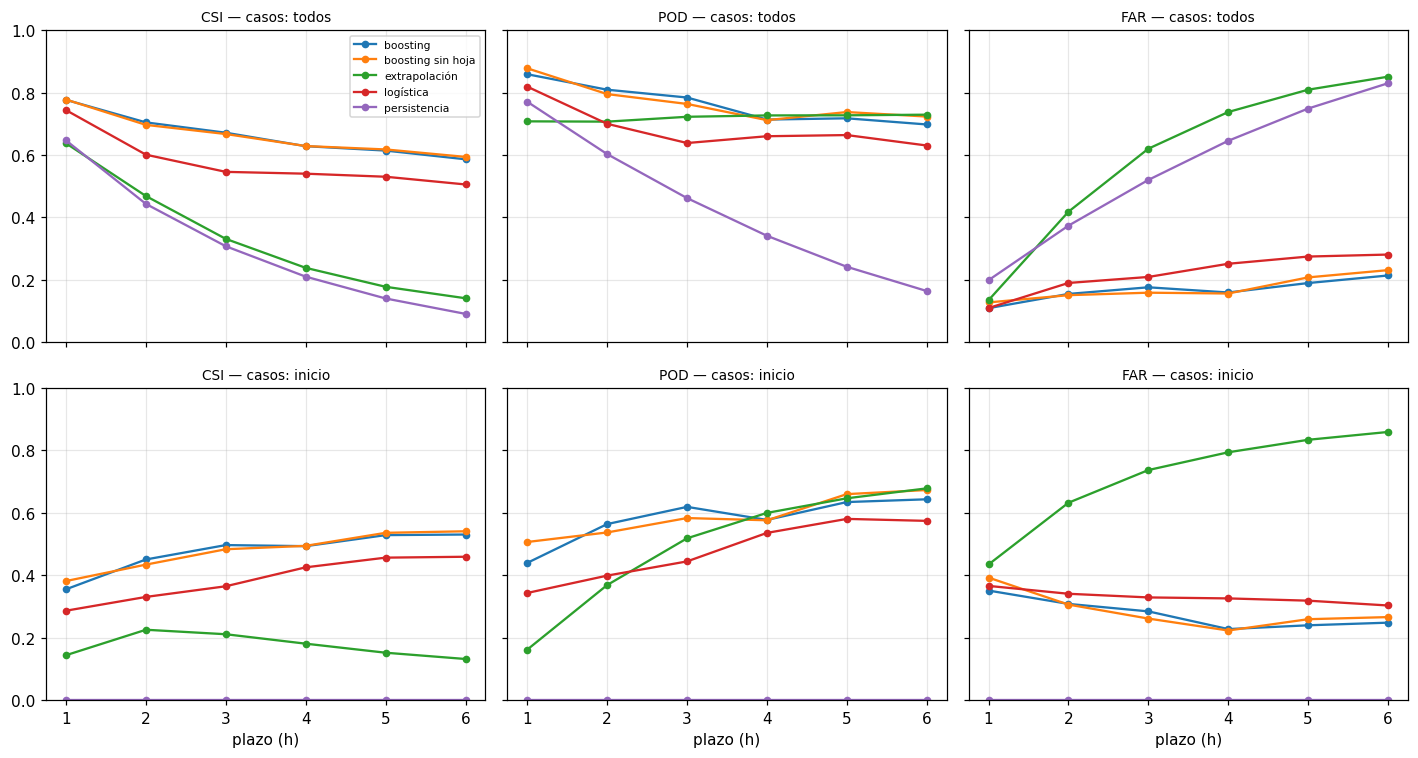

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey='row')
for i, sub in enumerate(['todos', 'inicio']):
    r = RES[(RES.casos == sub) & (RES.plazo != 'alerta6')]
    for j, met in enumerate(['CSI', 'POD', 'FAR']):
        ax = axs[i, j]
        for mod, g in r.groupby('modelo'):
            ax.plot(g['plazo'].astype(int), g[met], 'o-', ms=4, label=mod)
        ax.set_title(f'{met} — casos: {sub}', fontsize=9); ax.set_ylim(0, 1)
for ax in axs[-1]: ax.set_xlabel('plazo (h)')
axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.1 Calibración de las probabilidades

Si el modelo está bien calibrado, cuando dice "30 %" la helada debería ocurrir cerca del 30 % de las veces.

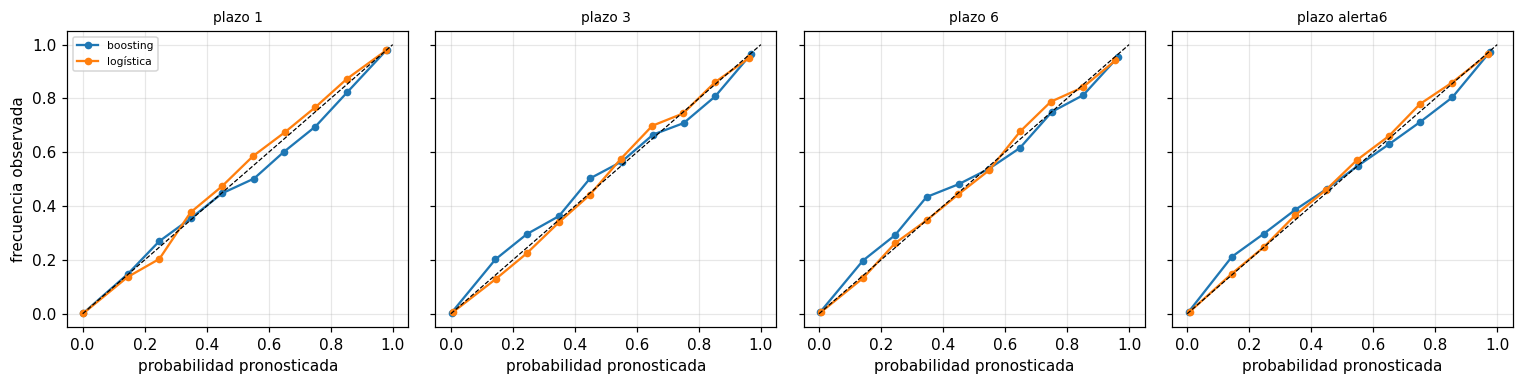

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
bins = np.linspace(0, 1, 11)
for ax, lead in zip(axs, [1, 3, 6, 'alerta6']):
    te = PRED[lead]
    for col, lab in [('p_hgb', 'boosting'), ('p_logit', 'logística')]:
        g = te.groupby(pd.cut(te[col], bins), observed=True)
        ax.plot(g[col].mean(), g['y'].mean(), 'o-', ms=4, label=lab)
    ax.plot([0, 1], [0, 1], 'k--', lw=.8); ax.set_title(f'plazo {lead}', fontsize=9)
    ax.set_xlabel('probabilidad pronosticada')
axs[0].set_ylabel('frecuencia observada'); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.2 Pronóstico de la temperatura mínima (regresor)

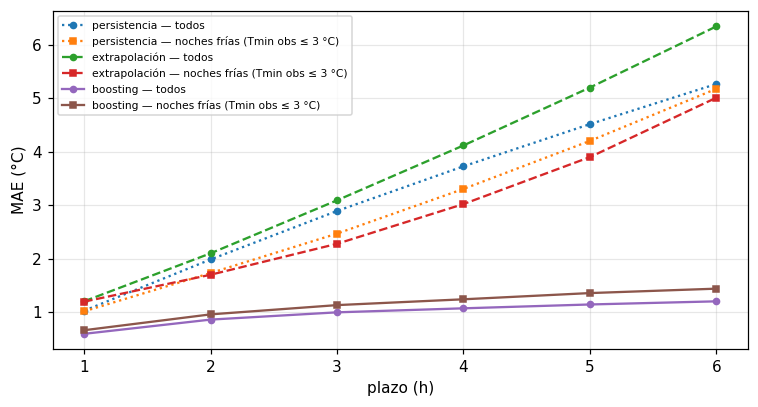

,plazo,casos,MAE persistencia,MAE extrapolación,MAE boosting,sesgo boosting
0,1,todos,1.03,1.21,0.60,0.02
1,1,noches frías (Tmin obs ≤ 3 °C),1.02,1.20,0.67,0.23
2,2,todos,1.99,2.10,0.86,0.03
3,2,noches frías (Tmin obs ≤ 3 °C),1.74,1.70,0.96,0.50
4,3,todos,2.89,3.09,1.00,0.02
5,3,noches frías (Tmin obs ≤ 3 °C),2.47,2.28,1.14,0.70
6,4,todos,3.73,4.12,1.08,-0.02
7,4,noches frías (Tmin obs ≤ 3 °C),3.31,3.02,1.24,0.80
8,5,todos,4.52,5.20,1.15,-0.01
9,5,noches frías (Tmin obs ≤ 3 °C),4.20,3.90,1.36,0.93


In [8]:
filas = []
for lead in LEADS:
    te = PRED[lead]
    for sub, t in [('todos', te), ('noches frías (Tmin obs ≤ 3 °C)', te[te[f'y_T_{lead}'] <= 3])]:
        y = t[f'y_T_{lead}']
        filas.append({'plazo': lead, 'casos': sub,
                      'MAE persistencia': mean_absolute_error(y, t['Tmin']),
                      'MAE extrapolación': mean_absolute_error(y, t['T_extrap']),
                      'MAE boosting': mean_absolute_error(y, t['T_reg']),
                      'sesgo boosting': (t['T_reg'] - y).mean()})
MAE = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(7, 3.8))
for c, ls in [('MAE persistencia', ':'), ('MAE extrapolación', '--'), ('MAE boosting', '-')]:
    for sub, mk in [('todos', 'o'), ('noches frías (Tmin obs ≤ 3 °C)', 's')]:
        g = MAE[MAE.casos == sub]
        ax.plot(g['plazo'], g[c], ls=ls, marker=mk, ms=4, label=f'{c[4:]} — {sub}')
ax.set_xlabel('plazo (h)'); ax.set_ylabel('MAE (°C)'); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
MAE.round(2)

### 3.3 Resultados por estación (plazo de 3 h y alerta de 6 h, boosting)

In [9]:
filas = []
for lead in [3, 'alerta6']:
    te = PRED[lead]; u = MOD[lead]['umbral']['hgb']
    for e, t in te.groupby('estacion'):
        if t['y'].sum() < 5: continue
        r = csi_pod_far(t['y'], t['p_hgb'] >= u)
        ti = t[t['inicio']]
        r_ini = csi_pod_far(ti['y'], ti['p_hgb'] >= u)
        filas.append({'estacion': ETQ[e], 'plazo': lead, 'horas_helada_test': int(t['y'].sum()),
                      'AUC': roc_auc_score(t['y'], t['p_hgb']), **r,
                      'CSI_inicio': r_ini['CSI'], 'POD_inicio': r_ini['POD']})
pd.DataFrame(filas).round(3)

,estacion,plazo,horas_helada_test,AUC,POD,FAR,CSI,CSI_inicio,POD_inicio
0,C2 USI,3,203,0.994,0.606,0.201,0.526,0.398,0.476
1,J1 Apata,3,229,0.999,0.882,0.086,0.815,0.706,0.814
2,J2 El Mantaro,3,323,0.999,0.892,0.103,0.809,0.710,0.801
3,J3 Muqui,3,199,0.999,0.844,0.134,0.747,0.631,0.748
4,P1 Camacani,3,391,0.988,0.650,0.251,0.534,0.408,0.511
5,P2 Illpa,3,1507,0.986,0.874,0.146,0.760,0.571,0.723
6,P3 Tahuaco,3,486,0.988,0.733,0.236,0.597,0.420,0.554
7,P4 Rincon de la Cruz,3,504,0.980,0.605,0.274,0.493,0.314,0.403
8,C2 USI,alerta6,493,0.991,0.793,0.229,0.642,0.542,0.714
9,J1 Apata,alerta6,444,0.998,0.883,0.084,0.817,0.703,0.798


## 4. ¿Qué variables importan?

Usamos la **importancia por permutación** (cuánto baja el AUC al desordenar cada variable) para el clasificador a 3 h, sobre una muestra del periodo de prueba. En la tabla de la sección 3, la comparación entre *boosting* y *boosting sin hoja* indica si la humedad de hoja aporta información.

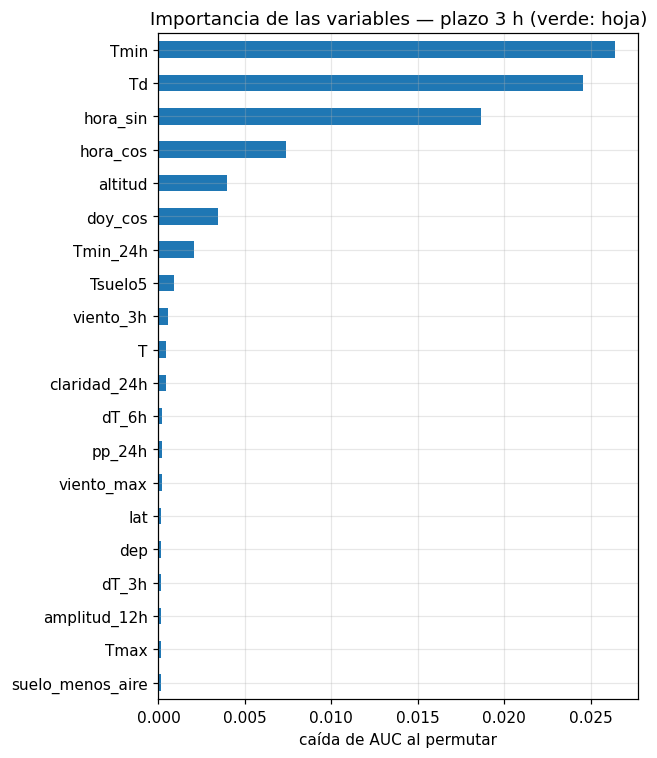

In [10]:
te = PRED[3].sample(min(30000, len(PRED[3])), random_state=SEED)
pi = permutation_importance(MOD[3]['modelos']['hgb'], te[FEATS], te['y'], scoring='roc_auc',
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(6, 7))
imp.tail(20).plot.barh(ax=ax, color=['tab:green' if f in HOJA_FEATS else 'tab:blue' for f in imp.tail(20).index])
ax.set_xlabel('caída de AUC al permutar'); ax.set_title('Importancia de las variables — plazo 3 h (verde: hoja)')
plt.tight_layout(); plt.show()

## 5. Ejemplos: noches de helada en el periodo de prueba

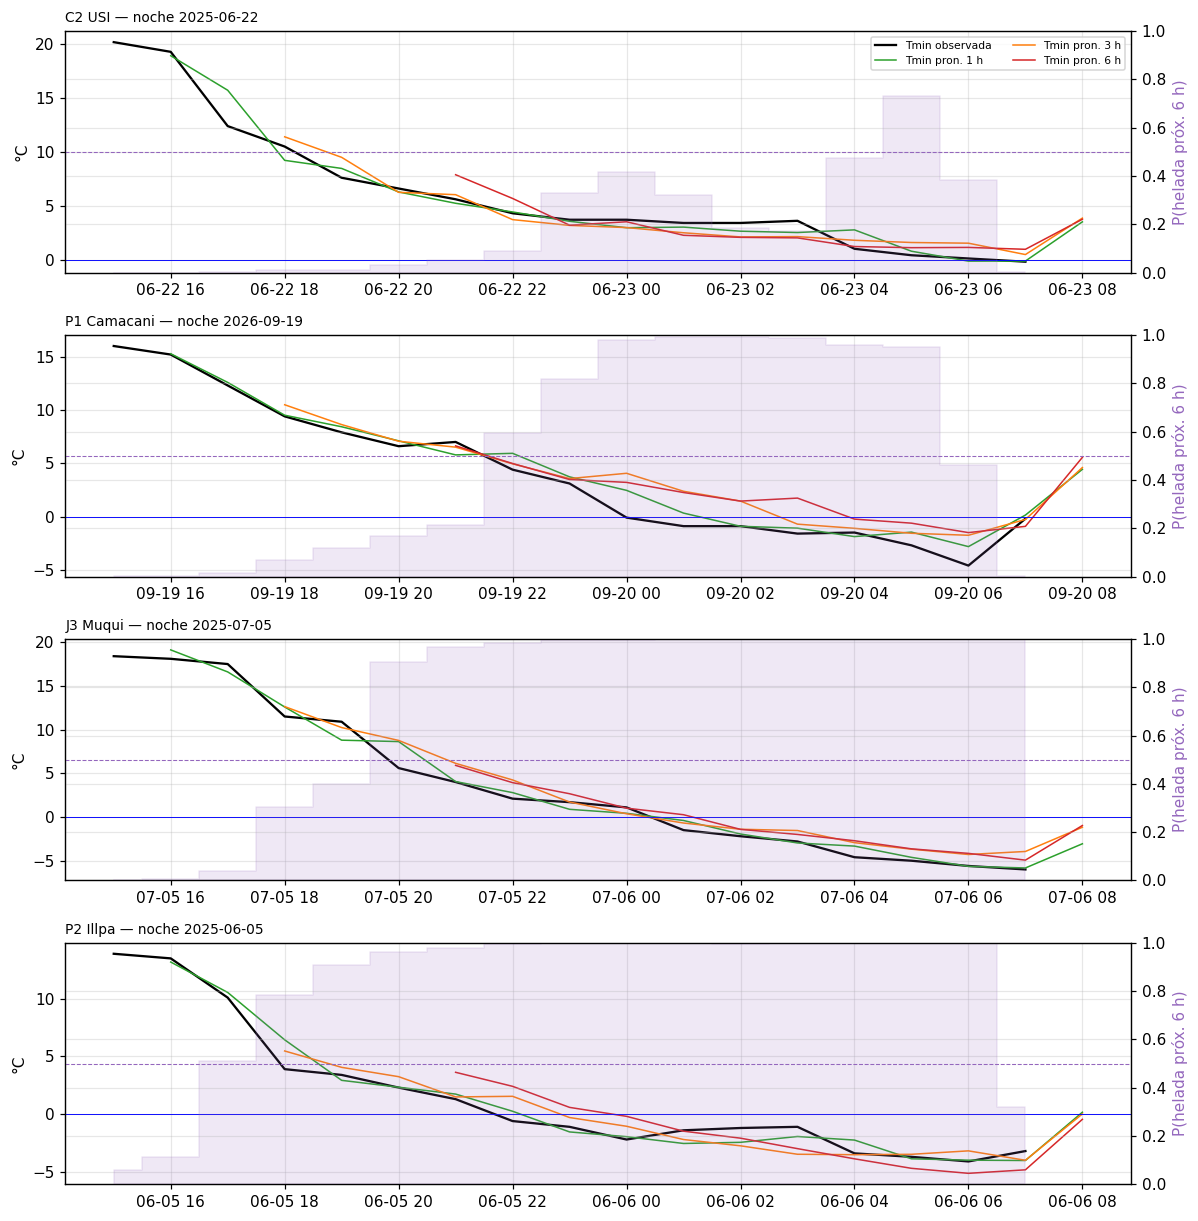

In [11]:
te1 = PRED[1]
hel = te1[te1['y']].groupby(['estacion', (te1[te1['y']].index - pd.Timedelta(hours=12)).normalize()]).size()
ejemplos = hel.sample(4, random_state=1).index if len(hel) >= 4 else hel.index
fig, axs = plt.subplots(len(ejemplos), 1, figsize=(11, 2.8 * len(ejemplos)), squeeze=False)
for ax, (e, noche) in zip(axs[:, 0], ejemplos):
    ini, fin = noche + pd.Timedelta(hours=15), noche + pd.Timedelta(hours=32)
    obs = DF[(DF.estacion == e)].loc[ini:fin]
    ax.plot(obs.index, obs['Tmin'], 'k-', lw=1.5, label='Tmin observada')
    for lead, c in [(1, 'tab:green'), (3, 'tab:orange'), (6, 'tab:red')]:
        p = PRED[lead][PRED[lead].estacion == e].loc[ini - pd.Timedelta(hours=lead):fin - pd.Timedelta(hours=lead)]
        ax.plot(p.index + pd.Timedelta(hours=lead), p['T_reg'], color=c, lw=1, label=f'Tmin pron. {lead} h')
    ax.axhline(0, color='b', lw=.6)
    ax2 = ax.twinx()
    p6 = PRED['alerta6'][PRED['alerta6'].estacion == e].loc[ini:fin]
    ax2.fill_between(p6.index, p6['p_hgb'], color='tab:purple', alpha=.15, step='mid')
    ax2.axhline(MOD['alerta6']['umbral']['hgb'], color='tab:purple', ls='--', lw=.7); ax2.set_ylim(0, 1)
    ax2.set_ylabel('P(helada próx. 6 h)', color='tab:purple')
    ax.set_title(f'{ETQ[e]} — noche {noche:%Y-%m-%d}', fontsize=9, loc='left'); ax.set_ylabel('°C')
axs[0, 0].legend(fontsize=7, loc='upper right', ncol=2); plt.tight_layout(); plt.show()

## 6. Modelo final y uso operativo

Reentrenamos con **entrenamiento + validación** (2022–2024), mantenemos los umbrales elegidos en validación y guardamos todo en `resultados/modelos/pronostico_heladas.joblib`.

`pronosticar(df_horario, estacion, t)` recibe la serie horaria de una estación, con las mismas columnas que `data/processed/horario`, y devuelve para cada plazo la probabilidad de helada, la Tmin pronosticada y si se emite alerta.

In [12]:
FINAL = {'feats': FEATS, 'leads': list(LEADS), 'umbral': {}, 'clf': {}, 'reg': {}}
for lead in [*LEADS, 'alerta6']:
    S, col = conjuntos(lead)
    tv = pd.concat([S['train'], S['val']])
    FINAL['clf'][lead] = hgb_clf().fit(tv[FEATS], tv[col] <= T_HELADA)
    if lead != 'alerta6':
        FINAL['reg'][lead] = hgb_reg().fit(tv[FEATS], tv[col])
    FINAL['umbral'][lead] = MOD[lead]['umbral']['hgb']
FINAL['claridad_ref'] = {e: DF[(DF.estacion == e) & (DF.conjunto != 'test')]
                            .groupby(lambda i: i.month)['rad_24h'].quantile(.95).to_dict() for e in ESTACIONES}
joblib.dump(FINAL, OUT / 'modelos' / 'pronostico_heladas.joblib')
print('guardado en', OUT / 'modelos' / 'pronostico_heladas.joblib')

guardado en /home/luismartin/Documentos/agro/E3/proy1/resultados/modelos/pronostico_heladas.joblib


In [13]:
def pronosticar(d_horario, est, t, modelo=FINAL):
    # d_horario: DataFrame con columna 'fecha' o índice horario, columnas originales de data/processed/horario
    d = d_horario.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    d = d.asfreq('h')
    X = predictores(d, est)
    ref = modelo['claridad_ref'].get(est)
    X['claridad_24h'] = (X['rad_24h'] / X.index.month.map(ref).values).clip(0, 1.2) if ref else np.nan
    x = X.loc[[pd.Timestamp(t)], modelo['feats']]
    filas = []
    for lead in [*modelo['leads'], 'alerta6']:
        p = modelo['clf'][lead].predict_proba(x)[0, 1]
        filas.append({'plazo': lead,
                      'hora_objetivo': (pd.Timestamp(t) + pd.Timedelta(hours=6 if lead == 'alerta6' else lead)),
                      'P_helada': round(p, 3),
                      'Tmin_pron': round(float(modelo['reg'][lead].predict(x)[0]), 1) if lead in modelo['reg'] else np.nan,
                      'alerta': p >= modelo['umbral'][lead]})
    return pd.DataFrame(filas)

# ejemplo: emisión a las 22:00 de una noche de helada del periodo de prueba
e = 'p2_illpa'
d_raw = pd.read_csv(DATA / 'horario' / f'{e}.csv', parse_dates=['fecha'])
t_ej = PRED[3][(PRED[3].estacion == e) & PRED[3]['y'] & (PRED[3].index.hour == 22)].index[0]
print(ETQ[e], 'emisión', t_ej)
pronosticar(d_raw, e, t_ej)

P2 Illpa emisión 2025-04-23 22:00:00


,plazo,hora_objetivo,P_helada,Tmin_pron,alerta
0,1,2025-04-23 23:00:00,0.365,0.7,False
1,2,2025-04-24 00:00:00,0.650,-0.0,True
2,3,2025-04-24 01:00:00,0.791,-1.1,True
3,4,2025-04-24 02:00:00,0.921,-1.9,True
4,5,2025-04-24 03:00:00,0.968,-2.6,True
5,6,2025-04-24 04:00:00,0.981,-3.4,True
6,alerta6,2025-04-24 04:00:00,0.945,NaN,True


## 7. Limitaciones y mejoras posibles

* **Temperatura a 2 m, no en la hoja**: con cielo despejado, la superficie del cultivo puede estar 2–3 °C más fría. Para alertas agronómicas conviene usar un umbral de 2 °C (`T_HELADA = 2`) y reentrenar.
* **Sin datos de nubosidad**: la nubosidad nocturna es el principal factor que frena el enfriamiento y aquí solo la aproximamos con la radiación diurna. Incorporar productos satelitales (GOES-16/18, cada 10 min) o un modelo numérico (GFS/ECMWF a través de Open-Meteo) mejoraría sobre todo los plazos de 4 a 6 h.
* **Datos faltantes**: el *boosting* tolera valores faltantes en los predictores, pero si falta la temperatura en la hora de emisión no se puede pronosticar.
* **Recalibración**: conviene reentrenar al final de cada temporada de heladas (octubre) con los datos nuevos.
* **Estaciones nuevas**: el modelo usa la altitud y la latitud, pero conviene validarlo localmente antes de usarlo en estaciones que no estuvieron en el entrenamiento.